# Complete Robot Inverse Kinematics

This notebook follows the same steps as `forward_kinematic_complete.ipynb`, but in reverse:

**triangle pose + connector link orientations → 5-bar end-effector positions → six motor angles.**

There are six motor angles, but the triangular platform has only three degrees of freedom. Therefore, the triangle pose alone does not define a unique solution. We also specify the three connector link orientations (from each triangle vertex to the corresponding 5-bar end effector), then choose the geometric branch closest to a reference posture.

The link lengths and fixed-point positions below follow the conventions used in the forward-kinematics notebook. Angles are in radians and lengths are in meters.

## 1 — Geometric parameters and desired pose

The pose is defined by vertex `A=(x_A,y_A)` and the angle `alpha` of side `AB`. The `connector_angles` specify the orientation of each link connecting a vertex to its corresponding end effector.

In [11]:
import math
import numpy as np
import matplotlib.pyplot as plt

# Five-bar link lengths (m), matching the forward-kinematics notebook
AB = BC = CD = DE = EA = CF = FF = 0.2
l_triangle = 0.2  # End-effector-to-vertex link length
d_triangle = 0.2  # Equilateral triangle side length

# Desired pose (m, radians): example constructed from theta_i = pi/2
x_A = 0.2985946040531197
y_A = 0.39687327124506444
alpha = 1.2150299244288536

# Direction from vertex to end effector for each leg
connector_angles = np.array([
    -3.022973726504686,
     2.4454863999368217,
     2.2003671467217503,
])

# Reference posture of each motor pair (radians)
reference_angles = np.tile([np.pi / 2, np.pi / 2], (3, 1))

if connector_angles.shape != (3,) or reference_angles.shape != (3, 2):
    raise ValueError("Il faut trois angles de connexion et trois paires d'angles de référence.")

## 2 — Desired vertices and 5-bar end effectors

Reconstruct the triangle vertices, then place each end effector at a distance `l_triangle` from its vertex in the selected connector direction.

In [12]:
A = np.array([x_A, y_A], dtype=float)
B = A + d_triangle * np.array([np.cos(alpha), np.sin(alpha)])
C = A + d_triangle * np.array([np.cos(alpha + np.pi / 3),
                                np.sin(alpha + np.pi / 3)])
platform_vertices = np.array([A, B, C])

connector_vectors = l_triangle * np.column_stack((
    np.cos(connector_angles), np.sin(connector_angles)
))
effectors_global = platform_vertices + connector_vectors

print("Sommets désirés A, B, C (m) :")
for name, point in zip(("A", "B", "C"), platform_vertices):
    print(f"{name} = ({point[0]:.6f}, {point[1]:.6f})")

print("\nEffecteurs désirés (m) :")
for i, point in enumerate(effectors_global, start=1):
    print(f"E{i} = ({point[0]:.6f}, {point[1]:.6f})")

Sommets désirés A, B, C (m) :
A = (0.298595, 0.396873)
B = (0.368256, 0.584349)
C = (0.171067, 0.550940)

Effecteurs désirés (m) :
E1 = (0.100000, 0.373205)
E2 = (0.214787, 0.712596)
E3 = (0.053307, 0.712596)


## 3 — Local mechanism coordinate frames

Each 5-bar mechanism is solved in its local frame, with the origin at the left motor and the `x`-axis pointing toward the right motor. Convert the global end-effector coordinates into these three frames before calculating the angles.

In [13]:
# Fixed motor positions, reused from compute_fixed_points() in the FK notebook
A1 = np.array([0.0, 0.0])
A2 = np.array([
    (0.5 + np.cos(np.pi / 3) + 2 * np.cos(np.pi / 6)
     + np.cos(5 * np.pi / 6 - 2 * np.pi / 5)) * 0.2,
    (np.sin(2 * np.pi / 5) + np.sin(4 * np.pi / 5) + 1
     + np.sin(np.pi / 3) + np.sin(2 * np.pi / 3)
     + np.sin(2 * np.pi / 3 + 2 * np.pi / 5)) * 0.2,
])
A3 = np.array([
    -(0.5 + np.cos(np.pi / 3) + np.cos(np.pi / 6)
      + np.cos(4 * np.pi / 5 - np.pi / 3
               + np.cos(2 * np.pi / 5 - np.pi / 3))) * 0.2,
    A2[1] + np.sin(2 * np.pi / 3) * 0.2,
])
base_angles = np.array([0.0, 2 * np.pi / 3, -2 * np.pi / 3])
left_anchors = np.array([A1, A2, A3])
right_anchors = left_anchors + EA * np.column_stack((
    np.cos(base_angles), np.sin(base_angles)
))

def global_to_local(point_global, point_left, point_right):
    """Convert a global point to a 5-bar frame whose x-axis is left -> right."""
    direction = point_right - point_left
    phi = np.arctan2(direction[1], direction[0])
    rotation = np.array([
        [np.cos(phi), -np.sin(phi)],
        [np.sin(phi),  np.cos(phi)],
    ])
    return rotation.T @ (np.asarray(point_global) - point_left)

effectors_local = np.array([
    global_to_local(effectors_global[i], left_anchors[i], right_anchors[i])
    for i in range(3)
])

print("Local effector coordinates (m):")
for i, point in enumerate(effectors_local, start=1):
    print(f"E{i}_local = ({point[0]:.6f}, {point[1]:.6f})")

Local effector coordinates (m):
E1_local = (0.100000, 0.373205)
E2_local = (0.100000, 0.373205)
E3_local = (0.100000, 0.373205)


## 4 — Geometric inverse kinematics of one 5-bar mechanism

For a known local end effector `E`, the left elbow `C` is at the intersection of circles `(A, AB)` and `(E, BC)`. The right elbow `D` is at the intersection of `(EA, DE)` and `(E, CD)`. Keep every valid combination of the two intersections instead of selecting just one branch. Label each chain **OUT** if its elbow bends counterclockwise (positive cross product) and **IN** if it bends clockwise. This convention is explicit and local to the leg frame. The 5-bar assembly mode (crossed or uncrossed) is also reported; it is distinct from the working mode.

In [14]:
from itertools import product

GEOMETRY_TOL = 1e-10

def cross_2d(vector_0, vector_1):
    return vector_0[0] * vector_1[1] - vector_0[1] * vector_1[0]

def circle_intersections(center_0, radius_0, center_1, radius_1, label):
    """Return the two intersections of circles, or an empty list if unreachable."""
    center_0 = np.asarray(center_0, dtype=float)
    center_1 = np.asarray(center_1, dtype=float)
    delta = center_1 - center_0
    distance = np.linalg.norm(delta)

    if distance <= GEOMETRY_TOL:
        if np.isclose(radius_0, radius_1, atol=GEOMETRY_TOL, rtol=0):
            raise ValueError(f"{label}: cercles confondus; la solution est singulière.")
        return []
    if distance > radius_0 + radius_1 + GEOMETRY_TOL:
        return []
    if distance < abs(radius_0 - radius_1) - GEOMETRY_TOL:
        return []

    along = (radius_0**2 - radius_1**2 + distance**2) / (2 * distance)
    height_squared = radius_0**2 - along**2
    if height_squared <= GEOMETRY_TOL:
        raise ValueError(f"{label}: cercles tangents ou presque tangents; configuration singulière.")

    unit = delta / distance
    perpendicular = np.array([-unit[1], unit[0]])
    foot = center_0 + along * unit
    height = np.sqrt(height_squared)
    return [foot + height * perpendicular, foot - height * perpendicular]

def wrap_angle(angle):
    return (angle + np.pi) % (2 * np.pi) - np.pi

def solve_5bar_inverse_all(endpoint):
    """Return every non-singular 5-bar IK branch for one target endpoint."""
    endpoint = np.asarray(endpoint, dtype=float)
    left_elbows = circle_intersections(
        [0.0, 0.0], AB, endpoint, BC, "Coude gauche"
    )
    right_elbows = circle_intersections(
        [EA, 0.0], DE, endpoint, CD, "Coude droit"
    )
    if not left_elbows or not right_elbows:
        raise ValueError(
            f"Effecteur local {endpoint} inaccessible par une ou les deux chaînes de la 5-barre."
        )

    candidates = []
    for elbow_left in left_elbows:
        for elbow_right in right_elbows:
            side = cross_2d(elbow_right - elbow_left, endpoint - elbow_left)
            if abs(side) <= GEOMETRY_TOL:
                continue
            angles = np.array([
                np.arctan2(elbow_left[1], elbow_left[0]),
                np.arctan2(elbow_right[1], elbow_right[0] - EA),
            ])
            left_bend = cross_2d(elbow_left, endpoint - elbow_left)
            right_bend = cross_2d(elbow_right - np.array([EA, 0.0]),
                                  endpoint - elbow_right)
            candidates.append({
                "angles": angles,
                "elbow_left": elbow_left,
                "elbow_right": elbow_right,
                "left_mode": "OUT" if left_bend > 0 else "IN",
                "right_mode": "OUT" if right_bend > 0 else "IN",
            "assembly_mode": "+" if side > 0 else "-",
            })

    if not candidates:
        raise ValueError(f"Aucune configuration valide pour l'effecteur {endpoint}.")
    return candidates

## 5 — Solving the three legs and verification

Each 5-bar mechanism can have up to four elbow combinations (IN/OUT for the left and right chains). Combine the possibilities across all three legs, giving up to `4^3 = 64` robot solutions for this pose and these connector orientations. The table lists their modes and motor angles, ordered from closest to farthest from `reference_angles`. Link collisions are not filtered.

In [15]:
leg_candidates = [
    solve_5bar_inverse_all(effectors_local[i]) for i in range(3)
]

def local_to_global(point_local, point_left, angle):
    rotation = np.array([
        [np.cos(angle), -np.sin(angle)],
        [np.sin(angle),  np.cos(angle)],
    ])
    return point_left + rotation @ point_local

all_solutions = []
for leg_combination in product(*leg_candidates):
    angles = np.array([candidate["angles"] for candidate in leg_combination])
    error = np.sum(wrap_angle(angles - reference_angles) ** 2)
    all_solutions.append({
        "angles": angles,
        "branches": leg_combination,
        "reference_error": error,
    })
all_solutions.sort(key=lambda solution: solution["reference_error"])

if not all_solutions:
    raise ValueError("Aucune solution complète pour cette pose et ces angles de connexion.")

# Choose the number to display in the figure (indexing starts at 1).
solution_to_plot = 1
if not 1 <= solution_to_plot <= len(all_solutions):
    raise ValueError(f"solution_to_plot doit être entre 1 et {len(all_solutions)}.")
selected_solution = all_solutions[solution_to_plot - 1]
joint_angles = selected_solution["angles"]
elbows_left_local = np.array([
    candidate["elbow_left"] for candidate in selected_solution["branches"]
])
elbows_right_local = np.array([
    candidate["elbow_right"] for candidate in selected_solution["branches"]
])
elbows_left_global = np.array([
    local_to_global(elbows_left_local[i], left_anchors[i], base_angles[i])
    for i in range(3)
])
elbows_right_global = np.array([
    local_to_global(elbows_right_local[i], left_anchors[i], base_angles[i])
    for i in range(3)
])

# Verify every listed branch against the link lengths and requested endpoint.
for solution in all_solutions:
    for i, candidate in enumerate(solution["branches"]):
        c = candidate["elbow_left"]
        d = candidate["elbow_right"]
        e = effectors_local[i]
        measured = np.array([
            np.linalg.norm(c), np.linalg.norm(e - c),
            np.linalg.norm(e - d), np.linalg.norm(d - [EA, 0.0]),
        ])
        if not np.allclose(measured, [AB, BC, CD, DE], atol=1e-9, rtol=0):
            raise AssertionError(f"Longueurs incorrectes, solution {solution}, jambe {i + 1}.")
        theta_left, theta_right = solution["angles"][i]
        c_from_angles = AB * np.array([np.cos(theta_left), np.sin(theta_left)])
        d_from_angles = np.array([EA, 0.0]) + DE * np.array([
            np.cos(theta_right), np.sin(theta_right)
        ])
        if not (np.allclose(c_from_angles, c, atol=1e-9, rtol=0)
                and np.allclose(d_from_angles, d, atol=1e-9, rtol=0)):
            raise AssertionError(f"Angles incorrects, solution {solution}, jambe {i + 1}.")

print(f"{len(all_solutions)} solutions complètes trouvées; "
      f"{[len(candidates) for candidates in leg_candidates]} branches par jambe.")
print("\nSolution | Modes de travail (gauche/droite) | Modes d'assemblage | Angles moteurs (degrés)")
for number, solution in enumerate(all_solutions, start=1):
    modes = " ; ".join(
        f"J{i + 1} {branch['left_mode']}/{branch['right_mode']}"
        for i, branch in enumerate(solution["branches"])
    )
    assembly = ", ".join(branch["assembly_mode"] for branch in solution["branches"])
    degrees = np.round(np.degrees(solution["angles"]).reshape(-1), 2)
    print(f"{number:02d} | {modes} | {assembly} | {degrees.tolist()}")

print(f"\nSolution affichée : {solution_to_plot} (la plus proche de la référence = 1).")
print("Tous les angles moteurs sont vérifiés par rapport aux longueurs de barres.")

27 solutions complètes trouvées; [3, 3, 3] branches par jambe.

Solution | Modes de travail (gauche/droite) | Modes d'assemblage | Angles moteurs (degrés)
01 | J1 IN/OUT ; J2 IN/OUT ; J3 IN/OUT | +, +, + | [90.0, 90.0, 90.0, 90.0, 90.0, 90.0]
02 | J1 OUT/OUT ; J2 IN/OUT ; J3 IN/OUT | +, +, + | [60.0, 90.0, 90.0, 90.0, 90.0, 90.0]
03 | J1 IN/IN ; J2 IN/OUT ; J3 IN/OUT | +, +, + | [90.0, 120.0, 90.0, 90.0, 90.0, 90.0]
04 | J1 IN/OUT ; J2 IN/OUT ; J3 IN/IN | +, +, + | [90.0, 90.0, 90.0, 90.0, 90.0, 120.0]
05 | J1 IN/OUT ; J2 IN/OUT ; J3 OUT/OUT | +, +, + | [90.0, 90.0, 90.0, 90.0, 60.0, 90.0]
06 | J1 IN/OUT ; J2 IN/IN ; J3 IN/OUT | +, +, + | [90.0, 90.0, 90.0, 120.0, 90.0, 90.0]
07 | J1 IN/OUT ; J2 OUT/OUT ; J3 IN/OUT | +, +, + | [90.0, 90.0, 60.0, 90.0, 90.0, 90.0]
08 | J1 OUT/OUT ; J2 IN/OUT ; J3 IN/IN | +, +, + | [60.0, 90.0, 90.0, 90.0, 90.0, 120.0]
09 | J1 OUT/OUT ; J2 IN/OUT ; J3 OUT/OUT | +, +, + | [60.0, 90.0, 90.0, 90.0, 60.0, 90.0]
10 | J1 IN/IN ; J2 IN/OUT ; J3 IN/IN | +, +, + 

## 6 — Displaying the inverse-kinematic configuration

Use the `solution_to_plot` slider to browse the configurations in the table; the drawing and IN/OUT modes update automatically. The `+` and `-` assembly modes are the signs of `(D-C) × (E-C)`.

In [16]:
import ipywidgets as widgets
from IPython.display import display

colors = ["tab:blue", "tab:orange", "tab:green"]

def plot_solution(solution_number):
    solution = all_solutions[solution_number - 1]
    fig, ax = plt.subplots(figsize=(8, 8))

    for i, color in enumerate(colors):
        left = left_anchors[i]
        right = right_anchors[i]
        vertex = platform_vertices[i]
        branch = solution["branches"][i]
        c = local_to_global(branch["elbow_left"], left, base_angles[i])
        d = local_to_global(branch["elbow_right"], left, base_angles[i])
        e = effectors_global[i]

        ax.plot([left[0], c[0], e[0], d[0], right[0]],
                [left[1], c[1], e[1], d[1], right[1]],
                "o-", color=color, linewidth=2, label=f"5-barre {i + 1}")
        ax.plot([e[0], vertex[0]], [e[1], vertex[1]], "--",
                color=color, linewidth=1.5)
        ax.scatter(*left, marker="s", color="black", zorder=4)
        ax.scatter(*right, marker="s", color="black", zorder=4)
        ax.text(e[0], e[1],
                f" E{i + 1} ({branch['left_mode']}/{branch['right_mode']})")

    closed_triangle = np.vstack((platform_vertices, platform_vertices[0]))
    ax.plot(closed_triangle[:, 0], closed_triangle[:, 1], "k-",
            linewidth=2, label="Triangle désiré")
    ax.scatter(platform_vertices[:, 0], platform_vertices[:, 1],
               marker="D", color="black", zorder=5)
    mode_summary = " | ".join(
        f"J{i + 1}:{branch['left_mode']}/{branch['right_mode']}"
        for i, branch in enumerate(solution["branches"])
    )
    ax.set_title(
        f"IK — solution {solution_number}/{len(all_solutions)} : {mode_summary}"
    )
    ax.set_xlabel("x (m)")
    ax.set_ylabel("y (m)")
    ax.axis("equal")
    ax.grid(True)
    ax.legend(loc="best")
    plt.show()
    plt.close(fig)

print("Solutions length: ", len(all_solutions))
solution_to_plot = widgets.IntSlider(
    value=1,
    min=1,
    max=len(all_solutions),
    step=1,
    description="Solution",
    continuous_update=False,
)
solution_output = widgets.interactive_output(
    plot_solution, {"solution_number": solution_to_plot}
)
display(widgets.VBox([solution_to_plot, solution_output]))

Solutions length:  27


## 7 — Full-turn connector animation

For this animation, the three motor-pivot pairs A1–A2, A3–A4, and A5–A6 are centered on the three edges of an equilateral base triangle and aligned with those edges. A deterministic grid search finds a reachable platform pose and connector directions so all three connector links can have the same 0.1 m length. Connector 1 rotates through a full turn; connectors 2 and 3 keep fixed directions. These settings apply only to the animation; the inverse-kinematics example above is unchanged. Each frame uses geometric inverse kinematics and selects the branch closest to the previous frame.

A reachable full-turn pose was found and rotated for all three connector choices:
  Connector 1: A=[0.75 0.17], reach margin=0.037 m
  Connector 2: A=[0.83777568 0.39131397], reach margin=0.037 m
  Connector 3: A=[0.60222432 0.35667296], reach margin=0.037 m
120 frames verified for each choice; all connectors are 0.10 m and the base triangle is 1.46 m.


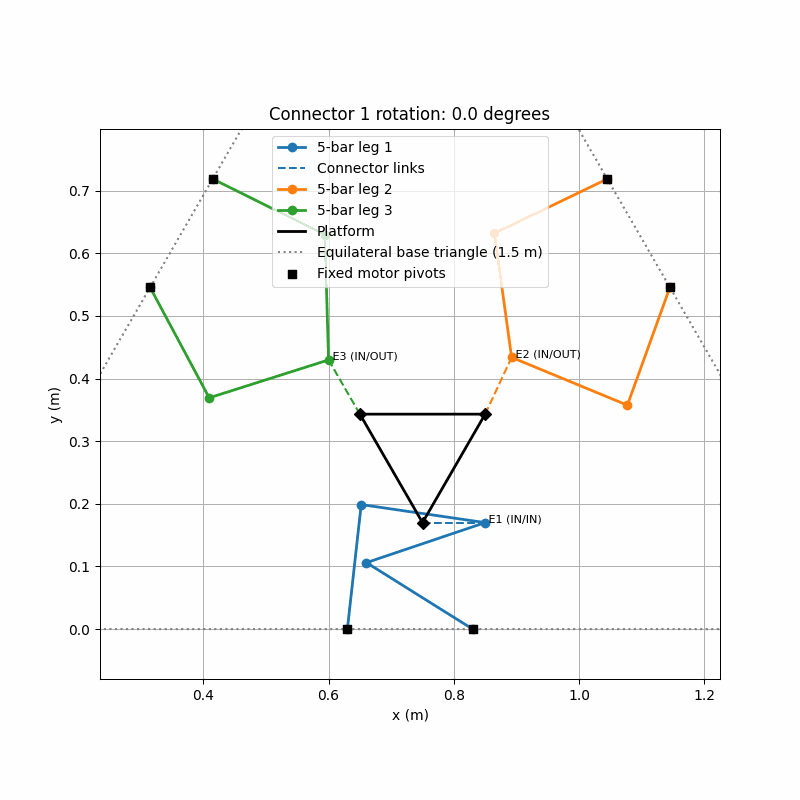

In [17]:
import os
from tempfile import TemporaryDirectory
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

animation_base_side = 1.46
animation_base_vertices = np.array([
    [0.0, 0.0], [animation_base_side, 0.0],
    [animation_base_side / 2, animation_base_side * np.sqrt(3) / 2],
])
animation_left_anchors, animation_right_anchors, animation_base_angles = [], [], []
for i in range(3):
    start, end = animation_base_vertices[i], animation_base_vertices[(i + 1) % 3]
    direction = (end - start) / animation_base_side
    midpoint = (start + end) / 2
    animation_left_anchors.append(midpoint - 0.5 * EA * direction)
    animation_right_anchors.append(midpoint + 0.5 * EA * direction)
    animation_base_angles.append(np.arctan2(direction[1], direction[0]))
animation_left_anchors = np.array(animation_left_anchors)
animation_right_anchors = np.array(animation_right_anchors)
animation_base_angles = np.array(animation_base_angles)

animation_connector_length = 0.1
animation_min_endpoint_reach = 0.02
animation_max_endpoint_reach = AB + BC - animation_min_endpoint_reach
animation_position_step = 0.05
animation_pose_angles = np.arange(-np.pi, np.pi, np.deg2rad(10.0))
animation_search_angles = np.arange(-np.pi, np.pi, np.deg2rad(5.0))
animation_search_directions = np.column_stack((
    np.cos(animation_search_angles), np.sin(animation_search_angles)
))
animation_rotation_angles = np.linspace(0.0, 2 * np.pi, 120, endpoint=False)
position_radius = animation_max_endpoint_reach - animation_connector_length
x_values = np.arange(
    animation_left_anchors[0, 0] - position_radius,
    animation_right_anchors[0, 0] + position_radius + animation_position_step / 2,
    animation_position_step,
)
y_values = np.arange(
    min(animation_left_anchors[0, 1], animation_right_anchors[0, 1]) - position_radius,
    max(animation_left_anchors[0, 1], animation_right_anchors[0, 1]) + position_radius + animation_position_step / 2,
    animation_position_step,
)

best_score, first_configuration = -np.inf, None
for y in y_values:
    for x in x_values:
        pose_A = np.array([x, y])
        pivot_distances = np.array([
            np.linalg.norm(pose_A - animation_left_anchors[0]),
            np.linalg.norm(pose_A - animation_right_anchors[0]),
        ])
        rotation_margin = min(
            np.min(np.abs(pivot_distances - animation_connector_length)
                   - animation_min_endpoint_reach),
            np.min(animation_max_endpoint_reach - pivot_distances - animation_connector_length),
        )
        if rotation_margin <= 0:
            continue
        for angle in animation_pose_angles:
            vertices = np.array([
                pose_A,
                pose_A + d_triangle * np.array([np.cos(angle), np.sin(angle)]),
                pose_A + d_triangle * np.array([
                    np.cos(angle + np.pi / 3), np.sin(angle + np.pi / 3)
                ]),
            ])
            fixed_angles = np.zeros(3)
            margins_for_pose = [rotation_margin]
            for i, vertex in enumerate(vertices[1:], start=1):
                endpoints = vertex + animation_connector_length * animation_search_directions
                distances = np.stack((
                    np.linalg.norm(endpoints - animation_left_anchors[i], axis=1),
                    np.linalg.norm(endpoints - animation_right_anchors[i], axis=1),
                ))
                margins = np.minimum(
                    distances - animation_min_endpoint_reach,
                    animation_max_endpoint_reach - distances,
                ).min(axis=0)
                direction_index = int(np.argmax(margins))
                fixed_angles[i] = animation_search_angles[direction_index]
                margins_for_pose.append(margins[direction_index])
            score = min(margins_for_pose)
            if score > best_score:
                best_score = score
                first_configuration = {
                    'pose_A': pose_A.copy(), 'pose_angle': angle,
                    'fixed_angles': fixed_angles, 'vertices': vertices.copy(),
                    'score': score,
                }
if first_configuration is None:
    raise ValueError('No reachable full-turn pose found for connector 1.')

animation_configurations = {}
# Use the base triangle's 120-degree symmetry to derive the other two valid poses.
base_center = animation_base_vertices.mean(axis=0)
for shift in range(3):
    turn = shift * 2 * np.pi / 3
    rotation = np.array([[np.cos(turn), -np.sin(turn)], [np.sin(turn), np.cos(turn)]])
    def rotate_point(point):
        return base_center + (point - base_center) @ rotation.T
    vertices = np.array([
        rotate_point(first_configuration['vertices'][(i - shift) % 3])
        for i in range(3)
    ])
    fixed_angles = np.zeros(3)
    for i in range(3):
        old_index = (i - shift) % 3
        if i != shift:
            fixed_angles[i] = first_configuration['fixed_angles'][old_index] + turn
    configuration = {
        'pose_A': vertices[0].copy(),
        'pose_angle': np.arctan2(*(vertices[1] - vertices[0])[::-1]),
        'fixed_angles': fixed_angles, 'vertices': vertices,
        'score': first_configuration['score'],
    }
    animation_configurations[shift + 1] = configuration

edge_midpoints = (animation_base_vertices + np.roll(animation_base_vertices, -1, axis=0)) / 2
pair_midpoints = (animation_left_anchors + animation_right_anchors) / 2
pair_lengths = np.linalg.norm(animation_right_anchors - animation_left_anchors, axis=1)
if not (np.allclose(pair_midpoints, edge_midpoints, atol=1e-12, rtol=0)
        and np.allclose(pair_lengths, EA, atol=1e-12, rtol=0)):
    raise AssertionError('Motor pivot pairs must be centered on the base triangle edges.')
print('A reachable full-turn pose was found and rotated for all three connector choices:')
for number, config in animation_configurations.items():
    print(f"  Connector {number}: A={config['pose_A']}, reach margin={config['score']:.3f} m")


def build_animation_frames(connector_number):
    config = animation_configurations[connector_number]
    rotating_index = connector_number - 1
    frames, previous_angles = [], reference_angles.copy()
    for rotation_angle in animation_rotation_angles:
        states = []
        for i, vertex in enumerate(config['vertices']):
            angle = rotation_angle if i == rotating_index else config['fixed_angles'][i]
            endpoint = vertex + animation_connector_length * np.array([np.cos(angle), np.sin(angle)])
            local_endpoint = global_to_local(endpoint, animation_left_anchors[i], animation_right_anchors[i])
            candidates = solve_5bar_inverse_all(local_endpoint)
            branch = min(candidates, key=lambda candidate: np.sum(wrap_angle(
                candidate['angles'] - previous_angles[i]
            ) ** 2))
            lengths = np.array([
                np.linalg.norm(branch['elbow_left']),
                np.linalg.norm(local_endpoint - branch['elbow_left']),
                np.linalg.norm(local_endpoint - branch['elbow_right']),
                np.linalg.norm(branch['elbow_right'] - np.array([EA, 0.0])),
                np.linalg.norm(endpoint - vertex),
            ])
            expected = np.array([AB, BC, CD, DE, animation_connector_length])
            if not np.allclose(lengths, expected, atol=1e-8, rtol=0):
                raise AssertionError(f'Incorrect link length for connector {connector_number}, frame {len(frames)}.')
            previous_angles[i] = branch['angles']
            states.append({'branch': branch, 'endpoint': endpoint, 'vertex': vertex})
        frames.append({'angle': rotation_angle, 'legs': states})
    return frames


animation_frames_by_connector = {
    number: build_animation_frames(number) for number in animation_configurations
}
print(f'{len(animation_rotation_angles)} frames verified for each choice; all connectors are '
      f'{animation_connector_length:.2f} m and the base triangle is {animation_base_side:.2f} m.')


def animate_connectors_in_sequence():
    frames_per_connector = len(animation_rotation_angles)
    connector_count = len(animation_configurations)
    fig, ax = plt.subplots(figsize=(8, 8))
    leg_lines, connector_lines, labels = [], [], []
    for i, color in enumerate(colors):
        line, = ax.plot([], [], 'o-', color=color, linewidth=2, label=f'5-bar leg {i + 1}')
        connector, = ax.plot([], [], '--', color=color, linewidth=1.5,
                             label='Connector links' if i == 0 else None)
        label = ax.text(0.0, 0.0, '', fontsize=8)
        leg_lines.append(line)
        connector_lines.append(connector)
        labels.append(label)

    platform_line, = ax.plot([], [], 'k-', linewidth=2, label='Platform')
    closed_base = np.vstack((animation_base_vertices, animation_base_vertices[0]))
    ax.plot(closed_base[:, 0], closed_base[:, 1], ':', color='0.5', linewidth=1.5,
            label=f'Equilateral base triangle ({animation_base_side:.1f} m)')
    ax.scatter(animation_left_anchors[:, 0], animation_left_anchors[:, 1], marker='s',
               color='black', zorder=4, label='Fixed motor pivots')
    ax.scatter(animation_right_anchors[:, 0], animation_right_anchors[:, 1], marker='s',
               color='black', zorder=4)
    vertex_markers = ax.scatter([], [], marker='D', color='black', zorder=5)

    all_vertices = np.vstack([
        configuration['vertices'] for configuration in animation_configurations.values()
    ])
    all_endpoints = np.array([
        state['endpoint']
        for frames in animation_frames_by_connector.values()
        for frame in frames
        for state in frame['legs']
    ])
    plot_points = np.vstack((animation_left_anchors, animation_right_anchors,
                             all_vertices, all_endpoints))
    padding = 0.08
    ax.set_xlim(plot_points[:, 0].min() - padding, plot_points[:, 0].max() + padding)
    ax.set_ylim(plot_points[:, 1].min() - padding, plot_points[:, 1].max() + padding)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')
    ax.grid(True)
    ax.legend(loc='best')

    def update(frame_index):
        connector_number = frame_index // frames_per_connector + 1
        local_frame_index = frame_index % frames_per_connector
        frame = animation_frames_by_connector[connector_number][local_frame_index]
        vertices = animation_configurations[connector_number]['vertices']
        closed_platform = np.vstack((vertices, vertices[0]))
        platform_line.set_data(closed_platform[:, 0], closed_platform[:, 1])
        vertex_markers.set_offsets(vertices)

        for i, state in enumerate(frame['legs']):
            branch = state['branch']
            left_elbow = local_to_global(
                branch['elbow_left'], animation_left_anchors[i], animation_base_angles[i]
            )
            right_elbow = local_to_global(
                branch['elbow_right'], animation_left_anchors[i], animation_base_angles[i]
            )
            endpoint, vertex = state['endpoint'], state['vertex']
            chain = np.array([animation_left_anchors[i], left_elbow, endpoint,
                              right_elbow, animation_right_anchors[i]])
            leg_lines[i].set_data(chain[:, 0], chain[:, 1])
            connector_lines[i].set_data([vertex[0], endpoint[0]], [vertex[1], endpoint[1]])
            labels[i].set_position((endpoint[0], endpoint[1]))
            labels[i].set_text(f" E{i + 1} ({branch['left_mode']}/{branch['right_mode']})")
        ax.set_title(
            f"Connector {connector_number} rotation: "
            f"{np.degrees(frame['angle']):.1f} degrees"
        )
        return (*leg_lines, *connector_lines, *labels, platform_line, vertex_markers)

    animation = FuncAnimation(
        fig, update, frames=connector_count * frames_per_connector,
        interval=50, blit=False, repeat=True,
    )
    with TemporaryDirectory() as temporary_directory:
        gif_path = os.path.join(temporary_directory, 'connector_sequence.gif')
        animation.save(gif_path, writer=PillowWriter(fps=20))
        with open(gif_path, 'rb') as gif_file:
            gif_data = gif_file.read()
    display(Image(data=gif_data, format='gif'))
    plt.close(fig)


animate_connectors_in_sequence()

In [19]:
%pip install imageio-ffmpeg
import os
import imageio_ffmpeg
from IPython.display import FileLink, display
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

winget_ffmpeg_links = r"C:\Users\victo\AppData\Local\Microsoft\WinGet\Links"
if os.path.isdir(winget_ffmpeg_links):
    path_entries = os.environ.get("PATH", "").split(os.pathsep)
    if winget_ffmpeg_links not in path_entries:
        os.environ["PATH"] = os.environ.get("PATH", "") + os.pathsep + winget_ffmpeg_links

plt.rcParams["animation.ffmpeg_path"] = imageio_ffmpeg.get_ffmpeg_exe()


def save_connector_video(connector_number):
    frames = animation_frames_by_connector[connector_number]
    fig, ax = plt.subplots(figsize=(8, 8))
    leg_lines, connector_lines, labels = [], [], []
    for i, color in enumerate(colors):
        line, = ax.plot([], [], 'o-', color=color, linewidth=2)
        connector, = ax.plot([], [], '--', color=color, linewidth=1.5)
        label = ax.text(0.0, 0.0, '', fontsize=8)
        leg_lines.append(line)
        connector_lines.append(connector)
        labels.append(label)

    platform_line, = ax.plot([], [], 'k-', linewidth=2)
    closed_base = np.vstack((animation_base_vertices, animation_base_vertices[0]))
    ax.plot(closed_base[:, 0], closed_base[:, 1], ':', color='0.5', linewidth=1.5)
    ax.scatter(animation_left_anchors[:, 0], animation_left_anchors[:, 1], marker='s', color='black', zorder=4)
    ax.scatter(animation_right_anchors[:, 0], animation_right_anchors[:, 1], marker='s', color='black', zorder=4)
    vertex_markers = ax.scatter([], [], marker='D', color='black', zorder=5)

    ax.set_xlim(0.2, 1.2)
    ax.set_ylim(-0.1, 1.1)
    ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('x (m)')
    ax.set_ylabel('y (m)')
    ax.grid(True)
    ax.set_title(f'Connector {connector_number}')

    def update(frame_index):
        frame = frames[frame_index]
        vertices = animation_configurations[connector_number]['vertices']
        closed_platform = np.vstack((vertices, vertices[0]))
        platform_line.set_data(closed_platform[:, 0], closed_platform[:, 1])
        vertex_markers.set_offsets(vertices)

        for i, state in enumerate(frame['legs']):
            branch = state['branch']
            left_elbow = local_to_global(branch['elbow_left'], animation_left_anchors[i], animation_base_angles[i])
            right_elbow = local_to_global(branch['elbow_right'], animation_left_anchors[i], animation_base_angles[i])
            endpoint, vertex = state['endpoint'], state['vertex']
            chain = np.array([
                animation_left_anchors[i], left_elbow, endpoint, right_elbow, animation_right_anchors[i]
            ])
            leg_lines[i].set_data(chain[:, 0], chain[:, 1])
            connector_lines[i].set_data([vertex[0], endpoint[0]], [vertex[1], endpoint[1]])
            labels[i].set_position((endpoint[0], endpoint[1]))
            labels[i].set_text(f" E{i + 1} ({branch['left_mode']}/{branch['right_mode']})")
        return (*leg_lines, *connector_lines, *labels, platform_line, vertex_markers)

    animation = FuncAnimation(
        fig, update, frames=len(frames), interval=50, blit=False, repeat=False
    )
    video_path = f"connector{connector_number}.mp4"
    animation.save(video_path, writer="ffmpeg", fps=12, dpi=150)
    plt.close(fig)
    return video_path

for connector_number in sorted(animation_frames_by_connector):
    video_path = save_connector_video(connector_number)
    display(FileLink(video_path))



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: C:\Users\victo\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.9_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\victo\Documents\info\robotics\Motion planning\Project2D_ENG654\connector1.mp4

c:\Users\victo\Documents\info\robotics\Motion planning\Project2D_ENG654\connector2.mp4

c:\Users\victo\Documents\info\robotics\Motion planning\Project2D_ENG654\connector3.mp4